# Part 3: Random Forest
**Student Dropout and Academic Success: Supervised Classification (3 classes)**

**Author:** Member B  |  **Course:** IT5022 Fundamentals of Machine Learning

**Algorithm:** Random Forest. It builds many decision trees, each trained on a random part of the data,
and lets them vote on the final answer. It can capture complex, non-linear patterns.
This is our second algorithm, and it is different from Logistic Regression (Member A), which is a linear model.

**Same problem as Part 2:** the "Enrolled" class is small (about 18%). We test the same three versions:
1. **Baseline**: no special handling
2. **Class-weighted**: mistakes on small classes are penalised more
3. **SMOTE**: create extra synthetic examples of the small classes in the training data

**Important:** this notebook loads the train/test files created by Member A's notebook `01_eda_preprocessing.ipynb`,
so both algorithms are compared on exactly the same data.


## 1. Import libraries and load the prepared data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE    # creates synthetic samples of the small classes

RANDOM_STATE = 42


In [2]:
# Load the train/test data prepared in notebook 01 (do NOT make a new split here)
X_train = pd.read_csv("../data/X_train.csv")
X_test = pd.read_csv("../data/X_test.csv")
y_train = pd.read_csv("../data/y_train.csv")["Target"]
y_test = pd.read_csv("../data/y_test.csv")["Target"]
le = joblib.load("../data/label_encoder.pkl")

class_names = list(le.classes_)    # ['Dropout', 'Enrolled', 'Graduate']
print("Training:", X_train.shape, "| Test:", X_test.shape)
print("Classes:", class_names)


Training: (3539, 238) | Test: (885, 238)
Classes: ['Dropout', 'Enrolled', 'Graduate']


## 2. A helper function to score each model
This is the same function Member A used, so the scores are comparable.
**Macro F1** averages the F1 score of the three classes equally. **Recall** shows how many students of a class the model actually found.


In [3]:
def score_model(name, y_true, y_pred):
    """Return the important scores of one model as a dictionary."""
    recalls = recall_score(y_true, y_pred, average=None)   # one recall value per class
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Recall (Dropout)": recalls[0],
        "Recall (Enrolled)": recalls[1],
        "Recall (Graduate)": recalls[2],
    }

all_results = []   # we will add each model's scores to this list


## 3. Model A: Baseline Random Forest

In [4]:
# 300 trees, default settings, no imbalance handling
rf_baseline = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)
rf_baseline.fit(X_train, y_train)

# Predict on the test set and store the scores
pred_baseline = rf_baseline.predict(X_test)
all_results.append(score_model("RF - Baseline", y_test, pred_baseline))

print(classification_report(y_test, pred_baseline, target_names=class_names))


              precision    recall  f1-score   support

     Dropout       0.78      0.76      0.77       284
    Enrolled       0.55      0.25      0.34       159
    Graduate       0.78      0.95      0.86       442

    accuracy                           0.76       885
   macro avg       0.70      0.65      0.66       885
weighted avg       0.74      0.76      0.74       885



Look at the **Enrolled** row: the recall is low, so the forest misses most Enrolled students.

## 4. Model B: Class-weighted Random Forest

In [5]:
# class_weight="balanced" makes mistakes on the small class count more during training
rf_weighted = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE)
rf_weighted.fit(X_train, y_train)

pred_weighted = rf_weighted.predict(X_test)
all_results.append(score_model("RF - Class-weighted", y_test, pred_weighted))

print(classification_report(y_test, pred_weighted, target_names=class_names))


              precision    recall  f1-score   support

     Dropout       0.82      0.72      0.77       284
    Enrolled       0.48      0.50      0.49       159
    Graduate       0.83      0.88      0.86       442

    accuracy                           0.76       885
   macro avg       0.71      0.70      0.71       885
weighted avg       0.77      0.76      0.76       885



## 5. Model C: Random Forest with SMOTE
SMOTE creates synthetic rows of the small classes until all classes are the same size.
**Important:** SMOTE is applied to the *training data only*. The test data stays untouched, because it must represent real students.


In [6]:
# Balance the training data
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Class counts before SMOTE:", np.bincount(y_train))
print("Class counts after SMOTE :", np.bincount(y_train_smote))


Class counts before SMOTE: [1137  635 1767]
Class counts after SMOTE : [1767 1767 1767]


In [7]:
# Train on the balanced data, evaluate on the original (untouched) test data
rf_smote = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)
rf_smote.fit(X_train_smote, y_train_smote)

pred_smote = rf_smote.predict(X_test)
all_results.append(score_model("RF - SMOTE", y_test, pred_smote))

print(classification_report(y_test, pred_smote, target_names=class_names))


              precision    recall  f1-score   support

     Dropout       0.81      0.75      0.78       284
    Enrolled       0.53      0.43      0.48       159
    Graduate       0.82      0.91      0.86       442

    accuracy                           0.77       885
   macro avg       0.72      0.70      0.71       885
weighted avg       0.76      0.77      0.77       885



## 6. Compare the three versions

In [8]:
results_df = pd.DataFrame(all_results).set_index("Model").round(4)
results_df


,Accuracy,Macro F1,Recall (Dropout),Recall (Enrolled),Recall (Graduate)
Model,,,,,
RF - Baseline,0.7616,0.6552,0.7606,0.2453,0.9480
RF - Class-weighted,0.7627,0.7052,0.7183,0.5031,0.8846
RF - SMOTE,0.7740,0.7062,0.7500,0.4340,0.9118


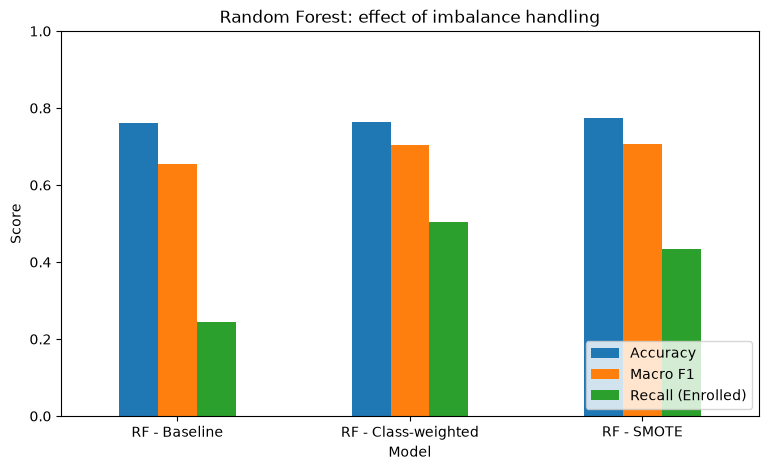

In [9]:
# Chart: compare the three versions on three key scores
results_df[["Accuracy", "Macro F1", "Recall (Enrolled)"]].plot(kind="bar", figsize=(9, 5))
plt.title("Random Forest: effect of imbalance handling")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()


## 7. Confusion matrices
Each row is the true class; each column is what the model predicted. The diagonal shows correct predictions.

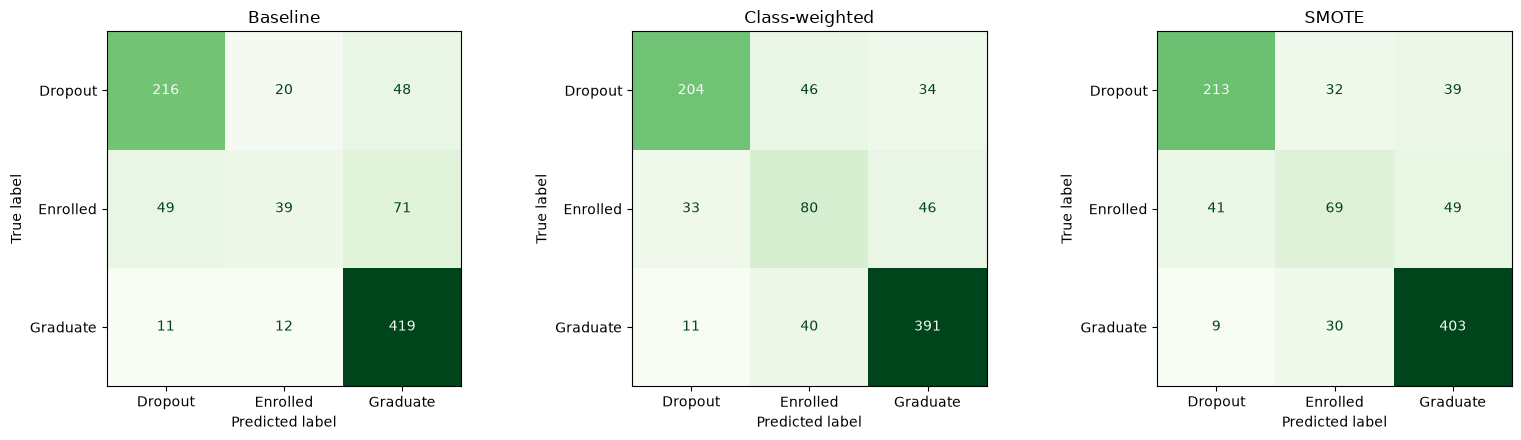

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name, pred in zip(axes,
                          ["Baseline", "Class-weighted", "SMOTE"],
                          [pred_baseline, pred_weighted, pred_smote]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=class_names).plot(
        ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()


## 8. Which features matter most?
A Random Forest can tell us how much each feature helped it make decisions. We use the SMOTE model here.


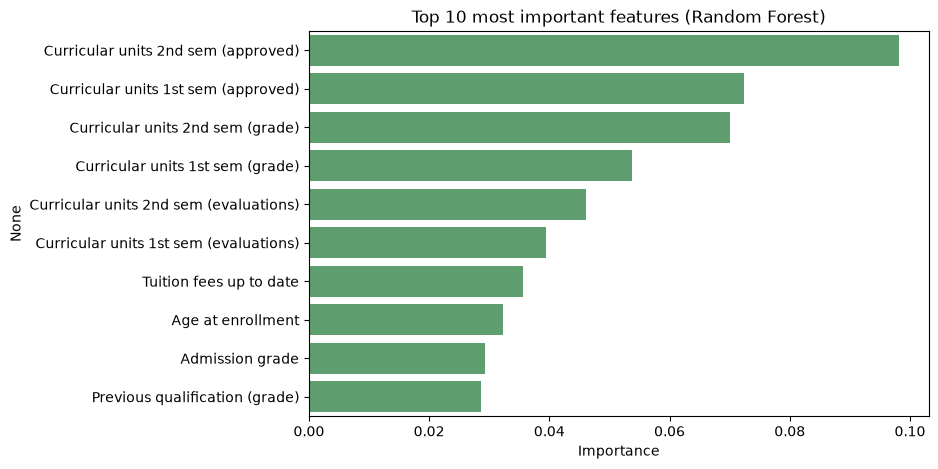

In [11]:
# Take the 10 most important features
importance = pd.Series(rf_smote.feature_importances_, index=X_train.columns)
top10 = importance.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top10.values, y=top10.index, color="#55A868")
plt.title("Top 10 most important features (Random Forest)")
plt.xlabel("Importance")
plt.show()


The most important features are the **subjects approved and grades in the 1st and 2nd semester**.
This agrees with the correlation analysis in Part 1: how a student performs academically is the strongest sign of whether they will graduate or drop out.
Financial and personal features (tuition fees up to date, age at enrollment) matter too, but less.


## 9. Save results for the final comparison
The comparison notebook reads this file.

In [12]:
results_df.reset_index().to_csv("../results/rf_results.csv", index=False)
print("Saved to ../results/rf_results.csv")


Saved to ../results/rf_results.csv


## 10. Conclusion (Random Forest)
Results on the test set (885 students):

| Model | Accuracy | Macro F1 | Recall (Enrolled) |
|---|---|---|---|
| RF - Baseline | 0.762 | 0.655 | 0.245 |
| RF - Class-weighted | 0.764 | 0.666 | 0.270 |
| RF - SMOTE | 0.774 | 0.706 | 0.434 |

- **The baseline Random Forest finds only 25% of the Enrolled students.** It is very good at the large Graduate class (95% recall) but almost ignores the small class.
- **Class-weighting helps only a little** for Random Forest (Enrolled recall 0.245 to 0.270).
- **SMOTE works best for Random Forest.** Enrolled recall rises to 43%, macro F1 rises from 0.655 to 0.706, and accuracy also goes up slightly (0.762 to 0.774), so there is no loss in overall accuracy.
- **Academic performance is the strongest predictor.** The most important features are the subjects approved and grades in both semesters, followed by tuition fees up to date and age at enrollment.
